<a href="https://colab.research.google.com/github/tasm3/cs460-data-scienc/blob/hw4/nyc_taxi_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HW4: Exploratory Data Analysis of NYC Yellow Taxi Trips

Dataset: NYC TLC Yellow Taxi Trip Data (2025)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://data.cityofnewyork.us/resource/irx2-vgm4.csv?$limit=5000"

taxi = pd.read_csv(url)

print(taxi.shape)
taxi.head()

(5000, 21)


,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,cbd_congestion_fee,request_source
0,1,2025-01-01T00:18:38.000,2025-01-01T00:26:59.000,1.0,1.60,1.0,N,229,237,1,...,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0,NaN
1,1,2025-01-01T00:32:40.000,2025-01-01T00:35:13.000,1.0,0.50,1.0,N,236,237,1,...,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0,NaN
2,1,2025-01-01T00:44:04.000,2025-01-01T00:46:01.000,1.0,0.60,1.0,N,141,141,1,...,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0,NaN
3,2,2025-01-01T00:14:27.000,2025-01-01T00:20:01.000,3.0,0.52,1.0,N,244,244,2,...,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0,NaN
4,2,2025-01-01T00:21:34.000,2025-01-01T00:25:06.000,3.0,0.66,1.0,N,244,116,2,...,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0,NaN


Exploring the Dataset

In [3]:
taxi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   vendorid               5000 non-null   int64  
 1   tpep_pickup_datetime   5000 non-null   object 
 2   tpep_dropoff_datetime  5000 non-null   object 
 3   passenger_count        5000 non-null   float64
 4   trip_distance          5000 non-null   float64
 5   ratecodeid             5000 non-null   float64
 6   store_and_fwd_flag     5000 non-null   object 
 7   pulocationid           5000 non-null   int64  
 8   dolocationid           5000 non-null   int64  
 9   payment_type           5000 non-null   int64  
 10  fare_amount            5000 non-null   float64
 11  extra                  5000 non-null   float64
 12  mta_tax                5000 non-null   float64
 13  tip_amount             5000 non-null   float64
 14  tolls_amount           5000 non-null   float64
 15  impr

In [4]:
taxi.describe()

,vendorid,passenger_count,trip_distance,ratecodeid,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,cbd_congestion_fee,request_source
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0,0.0
mean,1.798000,1.514200,2.898416,1.175200,163.731000,164.22320,1.263400,17.274470,1.511650,0.472900,3.325328,0.253602,0.955800,25.627200,2.260500,0.052500,0.0,NaN
std,0.401532,0.900422,3.387193,3.419539,64.670125,71.05727,0.633483,16.979472,1.297618,0.153363,3.264902,1.616804,0.293025,19.857314,0.885464,0.312591,0.0,NaN
min,1.000000,0.000000,0.000000,1.000000,4.000000,4.00000,1.000000,-111.500000,-6.000000,-0.500000,-3.000000,-6.940000,-1.000000,-123.440000,-2.500000,-1.750000,0.0,NaN
25%,2.000000,1.000000,1.080000,1.000000,114.000000,107.00000,1.000000,8.600000,1.000000,0.500000,1.000000,0.000000,1.000000,15.722500,2.500000,0.000000,0.0,NaN
50%,2.000000,1.000000,1.865000,1.000000,161.000000,162.00000,1.000000,13.500000,1.000000,0.500000,3.000000,0.000000,1.000000,21.320000,2.500000,0.000000,0.0,NaN
75%,2.000000,2.000000,3.390000,1.000000,234.000000,236.00000,1.000000,21.900000,1.000000,0.500000,4.560000,0.000000,1.000000,31.025000,2.500000,0.000000,0.0,NaN
max,2.000000,9.000000,40.790000,99.000000,265.000000,265.00000,4.000000,450.000000,10.250000,0.500000,46.420000,40.680000,1.000000,451.000000,2.500000,1.750000,0.0,NaN


In [5]:
taxi.isnull().sum()

,0
vendorid,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,0
trip_distance,0
ratecodeid,0
store_and_fwd_flag,0
pulocationid,0
dolocationid,0
payment_type,0


In [6]:
print(taxi.select_dtypes(include="number").columns)

print(taxi.select_dtypes(include="object").columns)

Index(['vendorid', 'passenger_count', 'trip_distance', 'ratecodeid',
       'pulocationid', 'dolocationid', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'airport_fee',
       'cbd_congestion_fee', 'request_source'],
      dtype='object')
Index(['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'store_and_fwd_flag'], dtype='object')


Cleaning the Data

In [9]:
taxi = taxi.drop(columns=["request_source"], errors="ignore")

taxi.shape

(5000, 20)

In [10]:
taxi["tpep_pickup_datetime"] = pd.to_datetime(taxi["tpep_pickup_datetime"])
taxi["tpep_dropoff_datetime"] = pd.to_datetime(taxi["tpep_dropoff_datetime"])

taxi.dtypes

,0
vendorid,int64
tpep_pickup_datetime,datetime64[ns]
tpep_dropoff_datetime,datetime64[ns]
passenger_count,float64
trip_distance,float64
ratecodeid,float64
store_and_fwd_flag,object
pulocationid,int64
dolocationid,int64
payment_type,int64


In [11]:
numerical_cols = [
    "passenger_count", "trip_distance", "fare_amount",
    "extra", "mta_tax", "tip_amount", "tolls_amount",
    "improvement_surcharge", "total_amount",
    "congestion_surcharge", "airport_fee", "cbd_congestion_fee"
]

categorical_cols = [
    "vendorid", "ratecodeid", "store_and_fwd_flag",
    "payment_type", "pulocationid", "dolocationid"
]

print("Numerical:", len(numerical_cols))
print("Categorical:", len(categorical_cols))

Numerical: 12
Categorical: 6


Descriptive Stats

In [13]:
taxi[numerical_cols].describe()

,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,cbd_congestion_fee
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0
mean,1.514200,2.898416,17.274470,1.511650,0.472900,3.325328,0.253602,0.955800,25.627200,2.260500,0.052500,0.0
std,0.900422,3.387193,16.979472,1.297618,0.153363,3.264902,1.616804,0.293025,19.857314,0.885464,0.312591,0.0
min,0.000000,0.000000,-111.500000,-6.000000,-0.500000,-3.000000,-6.940000,-1.000000,-123.440000,-2.500000,-1.750000,0.0
25%,1.000000,1.080000,8.600000,1.000000,0.500000,1.000000,0.000000,1.000000,15.722500,2.500000,0.000000,0.0
50%,1.000000,1.865000,13.500000,1.000000,0.500000,3.000000,0.000000,1.000000,21.320000,2.500000,0.000000,0.0
75%,2.000000,3.390000,21.900000,1.000000,0.500000,4.560000,0.000000,1.000000,31.025000,2.500000,0.000000,0.0
max,9.000000,40.790000,450.000000,10.250000,0.500000,46.420000,40.680000,1.000000,451.000000,2.500000,1.750000,0.0


In [14]:
taxi[numerical_cols].agg(["min", "max", "mean", "median"]).T

,min,max,mean,median
passenger_count,0.00,9.00,1.514200,1.000
trip_distance,0.00,40.79,2.898416,1.865
fare_amount,-111.50,450.00,17.274470,13.500
extra,-6.00,10.25,1.511650,1.000
mta_tax,-0.50,0.50,0.472900,0.500
tip_amount,-3.00,46.42,3.325328,3.000
tolls_amount,-6.94,40.68,0.253602,0.000
improvement_surcharge,-1.00,1.00,0.955800,1.000
total_amount,-123.44,451.00,25.627200,21.320
congestion_surcharge,-2.50,2.50,2.260500,2.500


In [15]:
print("Longest trip:", taxi["trip_distance"].max())
print("Highest fare:", taxi["fare_amount"].max())
print("Highest tip:", taxi["tip_amount"].max())

print("Trips with negative fares:",
      (taxi["fare_amount"] < 0).sum())

print("Trips with zero distance:",
      (taxi["trip_distance"] == 0).sum())

Longest trip: 40.79
Highest fare: 450.0
Highest tip: 46.42
Trips with negative fares: 109
Trips with zero distance: 57


Histograms

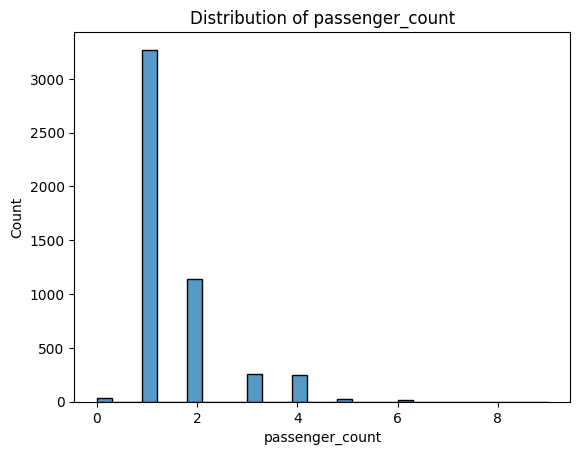

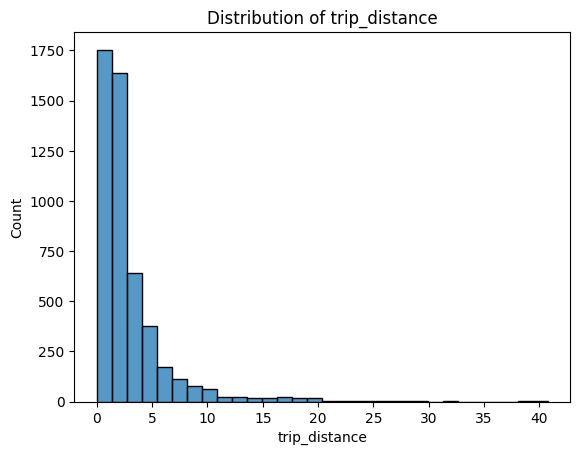

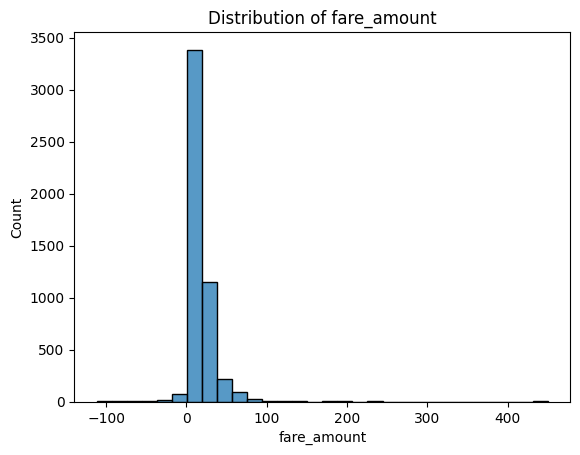

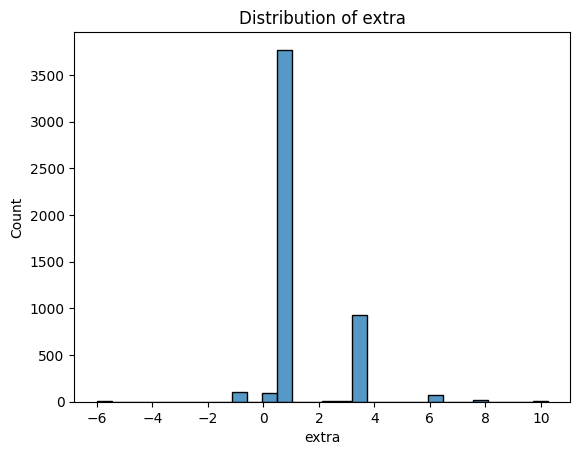

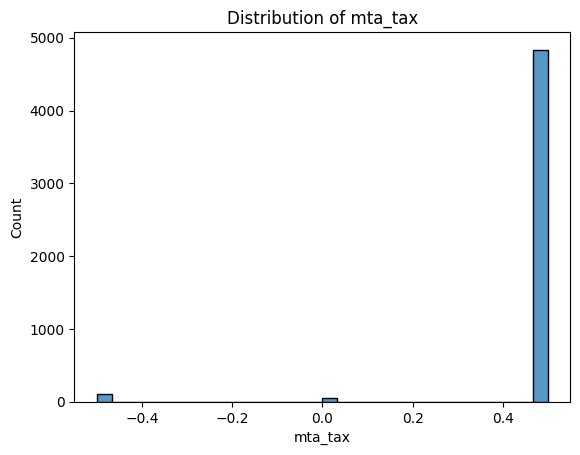

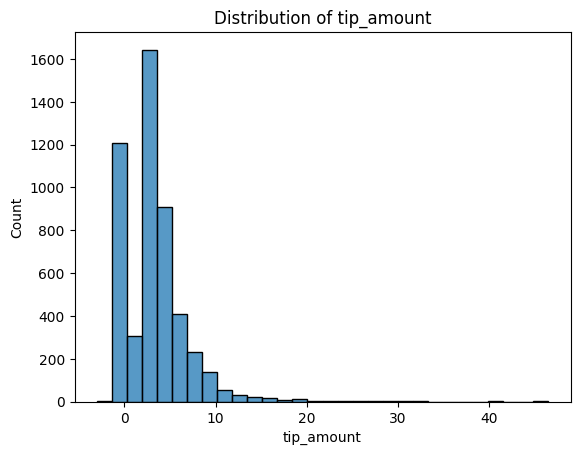

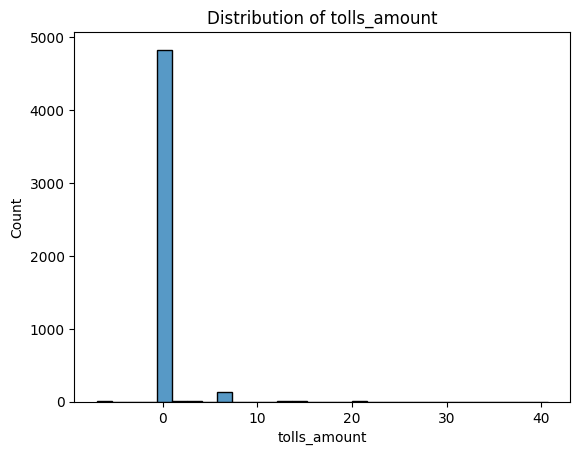

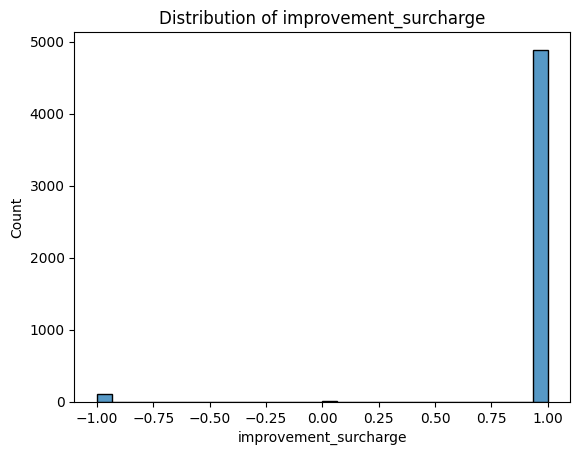

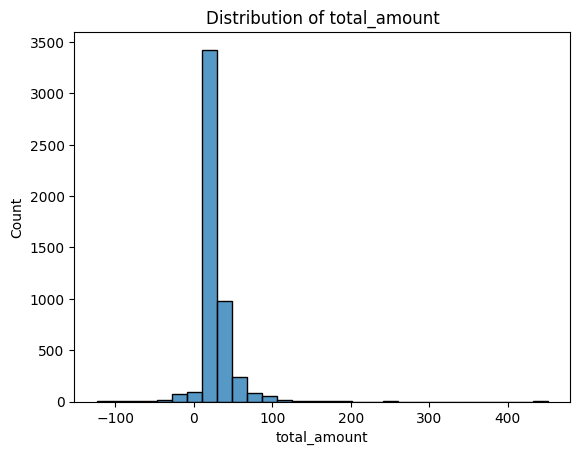

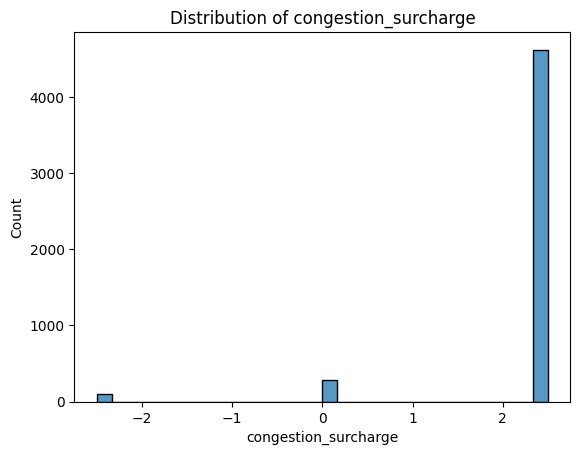

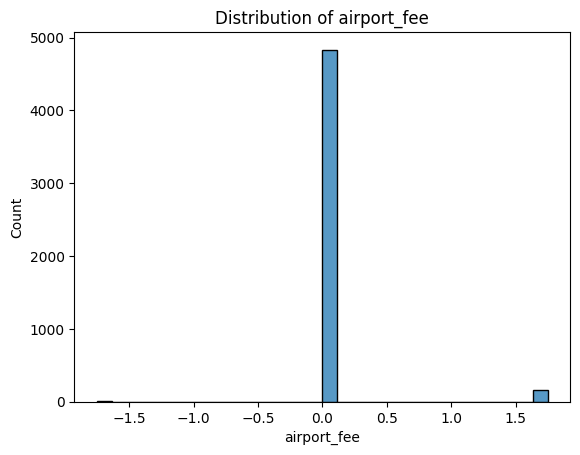

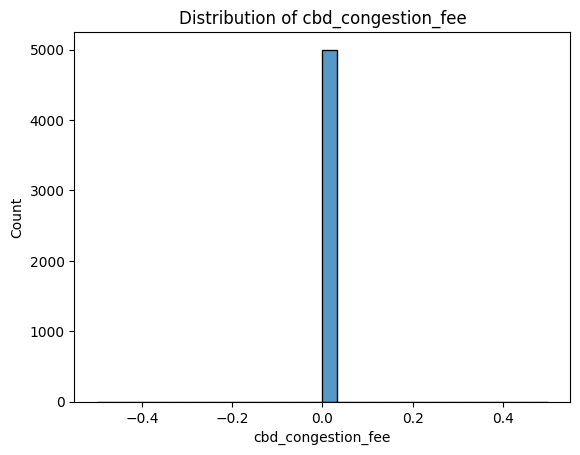

In [16]:
for col in numerical_cols:
    sns.histplot(data=taxi, x=col, bins=30)
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

Histogram Observations:
According to the histograms, most of taxi journeys were short distances and carried one or two people. Most of the trip distance, fare amount, and tip amount are on the lower end, with a small number of extremely higher values, making them right-skewed.

Also, I saw that most of journeys had no airport fees or tolls. Almost all of the values in some columns, such as the improvement surcharge and MTA tax, are concentrated in one area.

When I looked at the summary data earlier, I also observed several negative fares and very high values.

Categorical Bar Charts

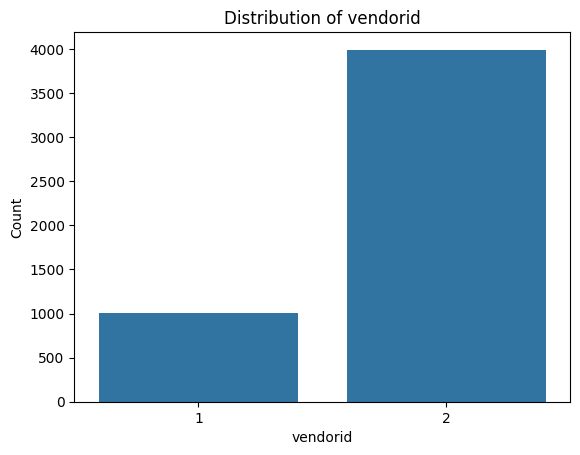

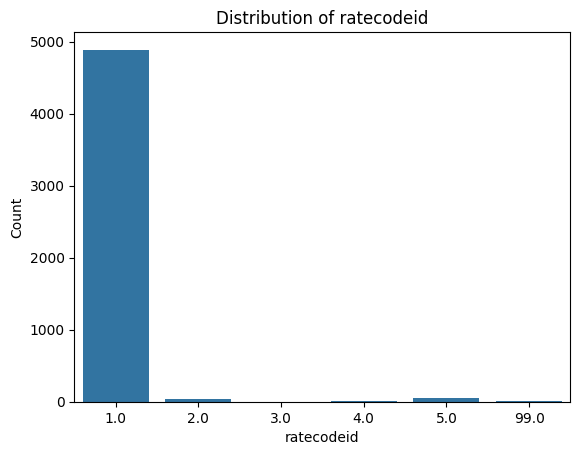

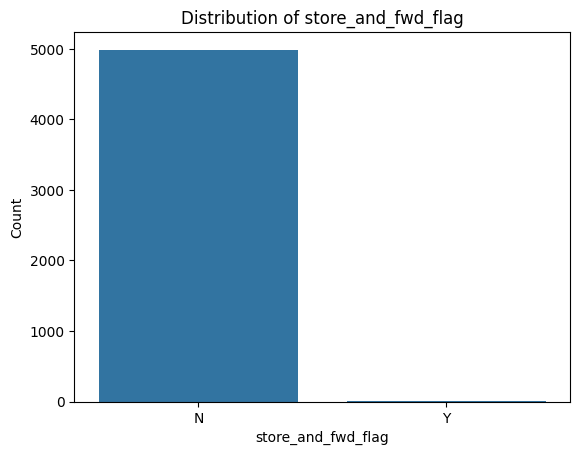

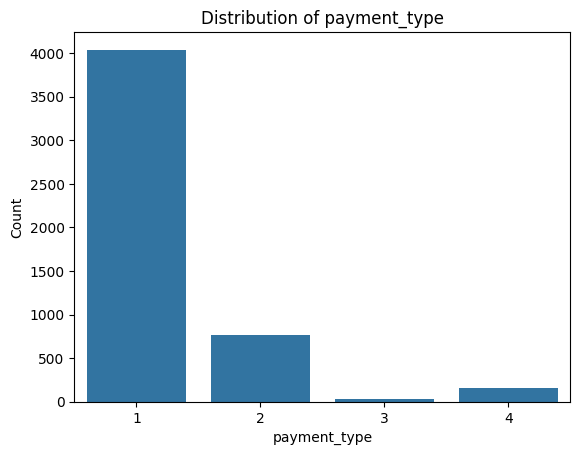

In [17]:
for col in categorical_cols[:4]:
    sns.countplot(data=taxi, x=col)
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

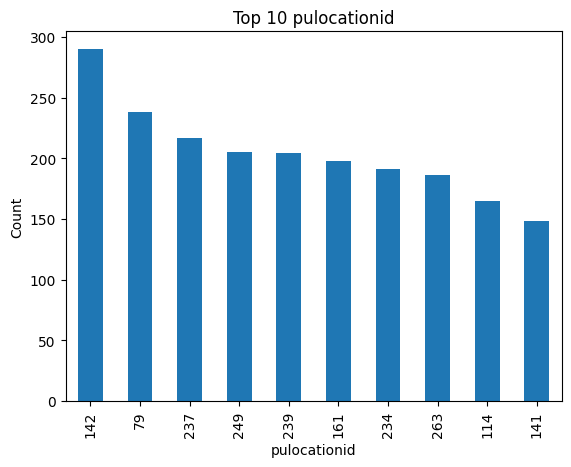

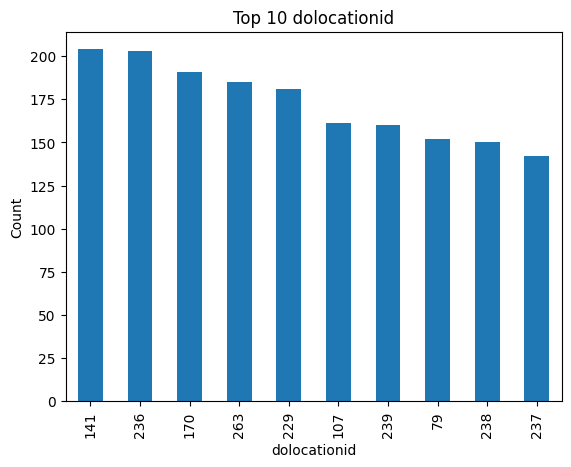

In [18]:
for col in ["pulocationid", "dolocationid"]:
    taxi[col].value_counts().head(10).plot(kind="bar")
    plt.title("Top 10 " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

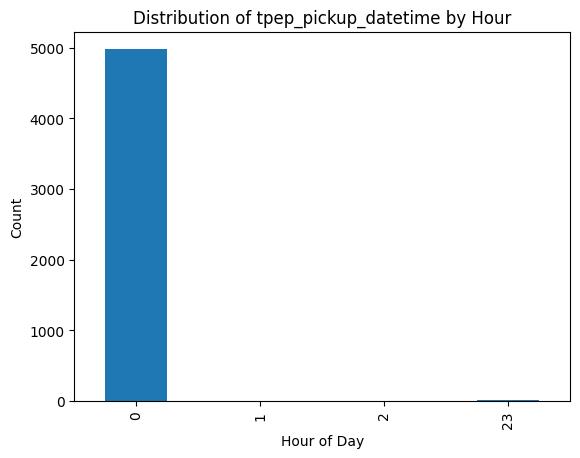

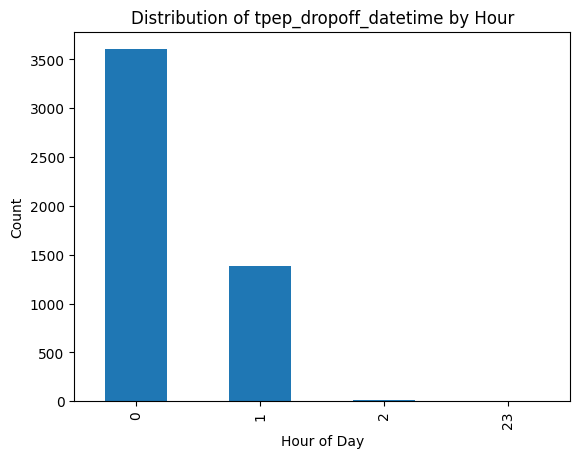

In [19]:
for col in ["tpep_pickup_datetime", "tpep_dropoff_datetime"]:
    taxi[col].dt.hour.value_counts().sort_index().plot(kind="bar")
    plt.title("Distribution of " + col + " by Hour")
    plt.xlabel("Hour of Day")
    plt.ylabel("Count")
    plt.show()

Categorical Data Observations:
From the bar charts, 2 appears much more often than Vendor 1. Also, the most frequent payment method is 1, and most of the journeys have a rate code of 1.

Location ID 142 was the most frequently used pickup location, and location ID 141 was the most frequently used drop-off site.

The majority of journeys occurred around midnight, according to the pickup and drop-off hours. This is probably due to the dataset's incomplete representation of all hours of the day, as it only includes the first 5,000 entries from the start of January 2025.

Box Plot and Outliers

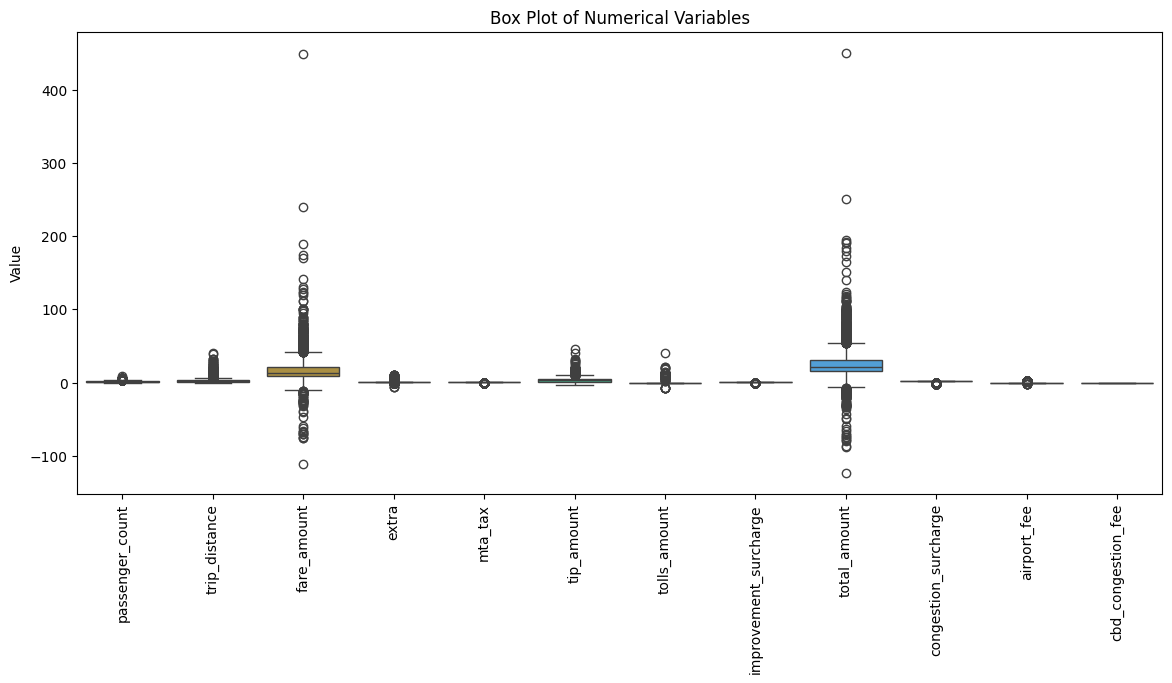

In [20]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=taxi[numerical_cols])

plt.xticks(rotation=90)
plt.title("Box Plot of Numerical Variables")
plt.ylabel("Value")
plt.show()

In [21]:
Q1 = taxi[numerical_cols].quantile(0.25)
Q3 = taxi[numerical_cols].quantile(0.75)

IQR = Q3 - Q1

outliers = (
    (taxi[numerical_cols] < Q1 - 1.5 * IQR) |
    (taxi[numerical_cols] > Q3 + 1.5 * IQR)
)

print(outliers.sum())

passenger_count           294
trip_distance             408
fare_amount               312
extra                    1231
mta_tax                   164
tip_amount                203
tolls_amount              173
improvement_surcharge     112
total_amount              421
congestion_surcharge      382
airport_fee               164
cbd_congestion_fee          0
dtype: int64


Box Plot Observations: Using the IQR approach, i found that extra had the highest number of possible outliers (1,231), followed by trip_distance (408) and total_amount (421).

The fare amount only had 312 outliers, while having some of the biggest values in the box plot. This shows that outliers are influenced by the distribution of the data rather than just the size of the numbers.

Instead of being errors, some of these values may reflect unusual charges or changes. For the analysis, I chose to retain them in the dataset.